<a href="https://colab.research.google.com/github/lnambiar18/Nambiar_Lohit_HW8_DSCI552/blob/main/Nambiar_Lohit_HW8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1>Nambiar_Lohit_HW8</h1></center>

Name: Lohit Nambiar
<br>
Github Username: lnambiar18
<br>
USC ID: 8395177707

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [38]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,roc_curve)
from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
from sklearn.model_selection import train_test_split

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [46]:
data = pd.read_csv("/content/wdbc.data", header = None)

print(data.shape)
ids = data.iloc[:, 0]
diagnosis = data.iloc[:, 1]
features = data.iloc[:, 2:]

data.head()

(569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Average scores over 30 runs:
train_accuracy     0.985161
train_precision    0.990594
train_recall       0.969412
train_f1           0.979879
train_auc          0.997198
test_accuracy      0.971681
test_precision     0.980867
test_recall        0.942857
test_f1            0.960941
test_auc           0.994020
dtype: float64

C values selected during the 30 runs:
best_C
0.1    29
1.0     1
Name: count, dtype: int64


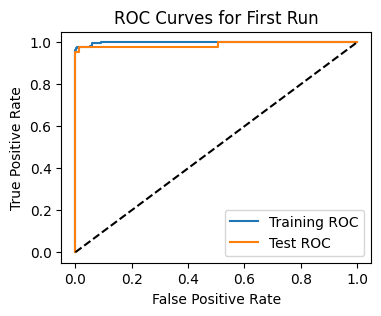

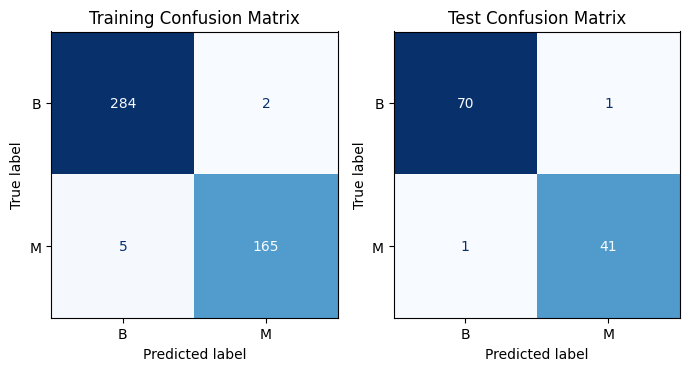

In [51]:
X = data.iloc[:, 2:]
y = data.iloc[:, 1]

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

all_results = []
rng = np.random.default_rng(1)

first_run = {}
for run in range(30):
    benign_indices = np.where(y == "B")[0]
    malignant_indices = np.where(y == "M")[0]

    test_benign = rng.choice(benign_indices, size = round(0.20 * len(benign_indices)), replace = False)
    test_malignant = rng.choice(malignant_indices, size = round(0.20 * len(malignant_indices)), replace = False)

    test_indices = np.concatenate([test_benign, test_malignant])
    train_indices = np.setdiff1d(np.arange(len(y)), test_indices)

    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]
    y_train = y.iloc[train_indices]
    y_test = y.iloc[test_indices]

    pipeline = make_pipeline(StandardScaler(), LinearSVC(penalty = "l1", dual = False, max_iter = 100000))

    search = GridSearchCV(pipeline, {"linearsvc__C": C_values}, cv = 5, scoring = "roc_auc")
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)
    train_decision = best_model.decision_function(X_train)
    test_decision = best_model.decision_function(X_test)

    row = {"run": run + 1, "best_C": search.best_params_["linearsvc__C"]}

    for set_name, true_labels, predictions, decision_scores in [("train", y_train, train_pred, train_decision), ("test", y_test, test_pred, test_decision)]:
        row[set_name + "_accuracy"] = accuracy_score(true_labels, predictions)
        row[set_name + "_precision"] = precision_score(true_labels, predictions, pos_label = "M", zero_division = 0)
        row[set_name + "_recall"] = recall_score(true_labels, predictions, pos_label = "M", zero_division = 0)
        row[set_name + "_f1"] = f1_score(true_labels, predictions, pos_label = "M", zero_division = 0)
        row[set_name + "_auc"] = roc_auc_score(true_labels == "M", decision_scores)

    all_results.append(row)

    if run == 0:
        first_run = {"y_train": y_train, "train_pred": train_pred, "train_decision": train_decision, "y_test": y_test, "test_pred": test_pred, "test_decision": test_decision}

results = pd.DataFrame(all_results)
score_columns = [column for column in results.columns if column.endswith(("accuracy", "precision", "recall", "f1", "auc"))]

print("Average scores over 30 runs:")
print(results[score_columns].mean())
print("\nC values selected during the 30 runs:")
print(results["best_C"].value_counts().sort_index())

plt.figure(figsize = (4, 3))
train_fpr, train_tpr, _ = roc_curve(first_run["y_train"] == "M", first_run["train_decision"])
test_fpr, test_tpr, _ = roc_curve(first_run["y_test"] == "M", first_run["test_decision"])
plt.plot(train_fpr, train_tpr, label = "Training ROC")
plt.plot(test_fpr, test_tpr, label = "Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for First Run")
plt.legend()
plt.show()

labels = ["B", "M"]
train_cm = confusion_matrix(first_run["y_train"], first_run["train_pred"], labels = labels)
test_cm = confusion_matrix(first_run["y_test"], first_run["test_pred"], labels = labels)

fig, axes = plt.subplots(1, 2, figsize = (7, 4))
ConfusionMatrixDisplay(confusion_matrix = train_cm,display_labels = labels ).plot(ax = axes[0], cmap = "Blues", values_format = "d", colorbar = False)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay(confusion_matrix = test_cm, display_labels = labels).plot(ax = axes[1], cmap = "Blues", values_format = "d", colorbar = False)
axes[1].set_title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [11]:
X = data.iloc[:, 2:]
y = data.iloc[:, 1]

rng = np.random.default_rng(1)

benign_indices = np.where(y == "B")[0]
malignant_indices = np.where(y == "M")[0]

test_benign = rng.choice(benign_indices, size = round(0.20 * len(benign_indices)), replace = False)
test_malignant = rng.choice(malignant_indices, size = round(0.20 * len(malignant_indices)), replace = False)

test_indices = np.concatenate([test_benign, test_malignant])
train_indices = np.setdiff1d(np.arange(len(y)), test_indices)

train_benign = train_indices[y.iloc[train_indices].to_numpy() == "B"]
train_malignant = train_indices[y.iloc[train_indices].to_numpy() == "M"]

labeled_benign = rng.choice(train_benign, size = len(train_benign) // 2, replace = False)
labeled_malignant = rng.choice(train_malignant, size = len(train_malignant) // 2, replace = False)

labeled_indices = np.concatenate([labeled_benign, labeled_malignant])
unlabeled_indices = np.setdiff1d(train_indices, labeled_indices)

X_labeled = X.iloc[labeled_indices]
y_labeled = y.iloc[labeled_indices]

model = make_pipeline(StandardScaler(), LinearSVC(penalty = "l1", dual = False, max_iter = 10000))

search = GridSearchCV(model, {"linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv = 5, scoring = "accuracy")
search.fit(X_labeled, y_labeled)
best_model = search.best_estimator_

print("Best C value:", search.best_params_["linearsvc__C"])
print("Labeled training rows:", len(labeled_indices))
print("Unlabeled training rows:", len(unlabeled_indices))
print("Test rows:", len(test_indices))

Best C value: 1
Labeled training rows: 228
Unlabeled training rows: 228
Test rows: 113


##### (B)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Average scores over 30 runs:
train_accuracy     0.975877
train_precision    0.980285
train_recall       0.954706
train_f1           0.967211
train_auc          0.993679
test_accuracy      0.966372
test_precision     0.968652
test_recall        0.941270
test_f1            0.954029
test_auc           0.989750
dtype: float64


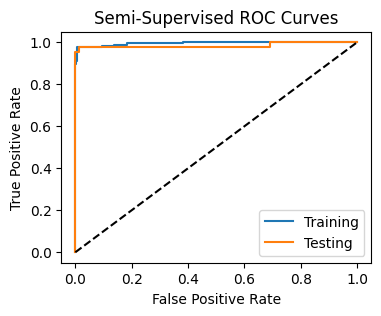

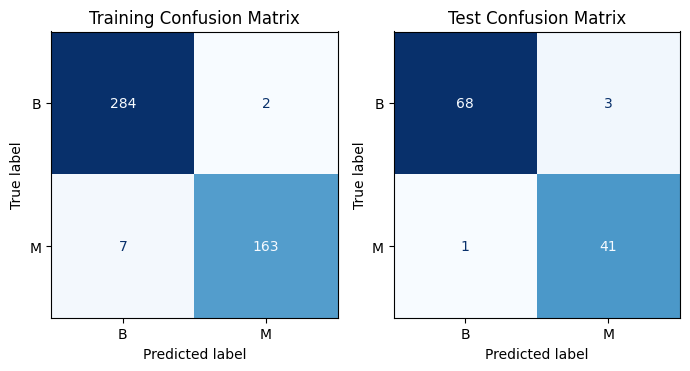

In [52]:
X = data.iloc[:, 2:]
y = data.iloc[:, 1]

all_scores = []
first_run = {}

for run in range(30):
    rng = np.random.default_rng(run + 1)
    benign = np.where(y == "B")[0]
    malignant = np.where(y == "M")[0]

    test_benign = rng.choice(benign, size = round(0.20 * len(benign)), replace = False)
    test_malignant = rng.choice(malignant, size=round(0.20 * len(malignant)), replace = False)

    test_indices = np.concatenate([test_benign, test_malignant])
    train_indices = np.setdiff1d(np.arange(len(y)), test_indices)

    train_benign = train_indices[y.iloc[train_indices].to_numpy() == "B"]
    train_malignant = train_indices[y.iloc[train_indices].to_numpy() == "M"]

    labeled_benign = rng.choice(train_benign, size = len(train_benign) // 2, replace = False)
    labeled_malignant = rng.choice(train_malignant, size = len(train_malignant) // 2, replace = False)

    labeled_indices = np.concatenate([labeled_benign, labeled_malignant])
    unlabeled_indices = np.setdiff1d(train_indices, labeled_indices)

    X_labeled = X.iloc[labeled_indices]
    y_labeled = y.iloc[labeled_indices]

    model = make_pipeline(StandardScaler(), LinearSVC(penalty = "l1", dual = False, max_iter = 10000))

    search = GridSearchCV(model, {"linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv = 5, scoring = "accuracy")
    search.fit(X_labeled, y_labeled)
    best_model = search.best_estimator_

    while len(unlabeled_indices) > 0:
        decision_scores = best_model.decision_function(X.iloc[unlabeled_indices])

        farthest_position = np.argmax(np.abs(decision_scores))
        chosen_index = unlabeled_indices[farthest_position]

        guessed_label = best_model.predict(X.iloc[[chosen_index]])[0]

        X_labeled = pd.concat([X_labeled, X.iloc[[chosen_index]]])
        y_labeled = pd.concat([y_labeled, pd.Series([guessed_label], index = [chosen_index])])

        unlabeled_indices = np.delete(unlabeled_indices, farthest_position)
        best_model.fit(X_labeled, y_labeled)

    train_y = y.iloc[train_indices]
    test_y = y.iloc[test_indices]

    train_pred = best_model.predict(X.iloc[train_indices])
    test_pred = best_model.predict(X.iloc[test_indices])

    train_decision = best_model.decision_function(X.iloc[train_indices])
    test_decision = best_model.decision_function(X.iloc[test_indices])

    scores = [accuracy_score(train_y, train_pred), precision_score(train_y, train_pred, pos_label = "M", zero_division = 0), recall_score(train_y, train_pred, pos_label = "M", zero_division = 0), f1_score(train_y, train_pred, pos_label = "M", zero_division = 0), roc_auc_score(train_y == "M", train_decision), accuracy_score(test_y, test_pred), precision_score(test_y, test_pred, pos_label = "M", zero_division = 0), recall_score(test_y, test_pred, pos_label = "M", zero_division = 0), f1_score(test_y, test_pred, pos_label = "M", zero_division = 0), roc_auc_score(test_y == "M", test_decision)]

    all_scores.append(scores)

    if run == 0:
        first_run = {"train_y": train_y, "train_pred": train_pred, "train_decision": train_decision, "test_y": test_y, "test_pred": test_pred, "test_decision": test_decision}

columns = ["train_accuracy", "train_precision", "train_recall", "train_f1", "train_auc", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_auc"]

results = pd.DataFrame(all_scores, columns=columns)
print("Average scores over 30 runs:")
print(results.mean())

plt.figure(figsize = (4, 3))
train_fpr, train_tpr, _ = roc_curve(first_run["train_y"] == "M", first_run["train_decision"])
test_fpr, test_tpr, _ = roc_curve(first_run["test_y"] == "M", first_run["test_decision"])
plt.plot(train_fpr, train_tpr, label = "Training")
plt.plot(test_fpr, test_tpr, label = "Testing")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Semi-Supervised ROC Curves")
plt.legend()
plt.show()

labels = ["B", "M"]
train_cm = confusion_matrix(first_run["train_y"], first_run["train_pred"], labels = labels)
test_cm = confusion_matrix(first_run["test_y"], first_run["test_pred"], labels = labels)

fig, axes = plt.subplots(1, 2, figsize = (7, 4))

ConfusionMatrixDisplay(confusion_matrix = train_cm, display_labels = labels).plot(ax = axes[0], cmap = "Blues", values_format = "d", colorbar = False)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay(confusion_matrix = test_cm, display_labels = labels).plot(ax = axes[1], cmap = "Blues", values_format = "d", colorbar = False)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

#### (iii) Unsupervised Learning

##### (A)

In [15]:
X = data.iloc[:, 2:]
y = data.iloc[:, 1]

all_runs = []

for run in range(30):
    rng = np.random.default_rng(run + 1)

    benign = np.where(y == "B")[0]
    malignant = np.where(y == "M")[0]

    test_benign = rng.choice(benign, size = round(0.20 * len(benign)), replace = False)
    test_malignant = rng.choice(malignant, size = round(0.20 * len(malignant)), replace = False)

    test_indices = np.concatenate([test_benign, test_malignant])
    train_indices = np.setdiff1d(np.arange(len(y)), test_indices)

    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    kmeans = KMeans(n_clusters = 2, init = "random", n_init=10, random_state = run + 1)
    kmeans.fit(X_train_scaled)

    all_runs.append({"train_y": y.iloc[train_indices], "test_y": y.iloc[test_indices], "X_train_scaled": X_train_scaled, "X_test_scaled": X_test_scaled, "kmeans": kmeans, "centers": kmeans.cluster_centers_})

I ran K-means with 10 different random starting points and kept the result with the lowest inertia. This makes it less likely that the algorithm gets stuck in a bad local minimum, though it can't guarantee that it found the absolute best one.

##### (B)

Average training scores over 30 runs:
accuracy     0.909795
precision    0.920514
recall       0.830000
f1           0.872798
auc          0.974092
dtype: float64


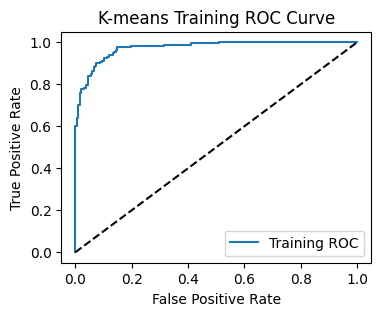

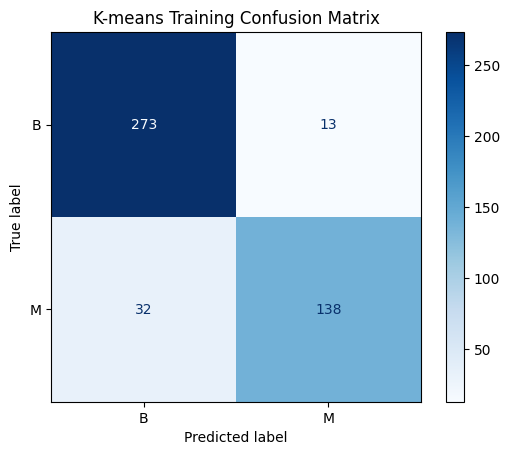

In [53]:
all_scores = []
first_run = {}

for run in range(30):
    kmeans = all_runs[run]["kmeans"]
    X_train_scaled = all_runs[run]["X_train_scaled"]
    train_y = all_runs[run]["train_y"]

    centers = kmeans.cluster_centers_
    distances = kmeans.transform(X_train_scaled)

    cluster_labels = []

    for cluster in range(2):
        closest_30 = np.argsort(distances[:, cluster])[:30]
        closest_labels = train_y.iloc[closest_30]
        majority_label = closest_labels.value_counts().idxmax()
        cluster_labels.append(majority_label)

    train_clusters = kmeans.labels_
    train_pred = np.array([cluster_labels[c] for c in train_clusters])

    weights = np.exp(-distances)
    probabilities = weights / weights.sum(axis = 1, keepdims = True)

    malignant_score = np.zeros(len(train_y))

    for cluster in range(2):
        if cluster_labels[cluster] == "M":
            malignant_score += probabilities[:, cluster]

    scores = {"accuracy": accuracy_score(train_y, train_pred), "precision": precision_score(train_y, train_pred, pos_label = "M", zero_division = 0), "recall": recall_score(train_y, train_pred, pos_label = "M", zero_division = 0), "f1": f1_score(train_y, train_pred, pos_label = "M", zero_division = 0), "auc": roc_auc_score(train_y == "M", malignant_score)}
    all_scores.append(scores)

    if run == 0:
        first_run = {"train_y": train_y, "train_pred": train_pred, "malignant_score": malignant_score}

results = pd.DataFrame(all_scores)

print("Average training scores over 30 runs:")
print(results.mean())

fpr, tpr, _ = roc_curve(first_run["train_y"] == "M", first_run["malignant_score"])

plt.figure(figsize = (4, 3))
plt.plot(fpr, tpr, label="Training ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-means Training ROC Curve")
plt.legend()
plt.show()

labels = ["B", "M"]
train_cm = confusion_matrix(first_run["train_y"], first_run["train_pred"], labels = labels)
ConfusionMatrixDisplay(confusion_matrix = train_cm,display_labels = labels).plot(cmap = "Blues", values_format = "d")
plt.title("K-means Training Confusion Matrix")
plt.show()

##### (C)

Average test scores over 30 runs:
accuracy     0.908850
precision    0.920987
recall       0.826984
f1           0.870541
auc          0.975799
dtype: float64


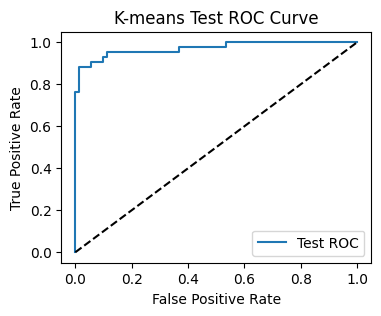

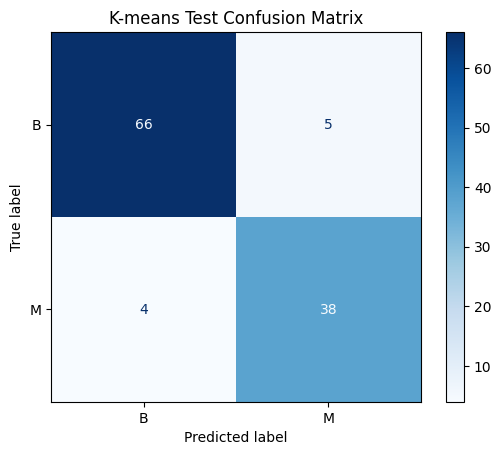

In [54]:
all_test_scores = []
first_test_run = {}

for run in range(30):
    kmeans = all_runs[run]["kmeans"]
    X_train_scaled = all_runs[run]["X_train_scaled"]
    X_test_scaled = all_runs[run]["X_test_scaled"]
    train_y = all_runs[run]["train_y"]
    test_y = all_runs[run]["test_y"]

    train_distances = kmeans.transform(X_train_scaled)
    cluster_labels = []

    for cluster in range(2):
        closest_30 = np.argsort(train_distances[:, cluster])[:30]
        closest_labels = train_y.iloc[closest_30]
        majority_label = closest_labels.value_counts().idxmax()
        cluster_labels.append(majority_label)

    test_clusters = kmeans.predict(X_test_scaled)
    test_pred = np.array([cluster_labels[c] for c in test_clusters])

    test_distances = kmeans.transform(X_test_scaled)
    weights = np.exp(-test_distances)
    probabilities = weights / weights.sum(axis = 1, keepdims = True)

    malignant_score = np.zeros(len(test_y))

    for cluster in range(2):
        if cluster_labels[cluster] == "M":
            malignant_score += probabilities[:, cluster]

    scores = {"accuracy": accuracy_score(test_y, test_pred), "precision": precision_score(test_y, test_pred, pos_label = "M", zero_division = 0), "recall": recall_score(test_y, test_pred, pos_label = "M", zero_division = 0), "f1": f1_score(test_y, test_pred, pos_label = "M", zero_division = 0), "auc": roc_auc_score(test_y == "M", malignant_score)}
    all_test_scores.append(scores)

    if run == 0:
        first_test_run = {"test_y": test_y, "test_pred": test_pred, "malignant_score": malignant_score}

test_results = pd.DataFrame(all_test_scores)

print("Average test scores over 30 runs:")
print(test_results.mean())

fpr, tpr, _ = roc_curve(first_test_run["test_y"] == "M", first_test_run["malignant_score"])

plt.figure(figsize = (4, 3))
plt.plot(fpr, tpr, label = "Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-means Test ROC Curve")
plt.legend()
plt.show()

labels = ["B", "M"]
test_cm = confusion_matrix(first_test_run["test_y"], first_test_run["test_pred"], labels = labels)
ConfusionMatrixDisplay(confusion_matrix = test_cm, display_labels = labels).plot(cmap = "Blues", values_format = "d")
plt.title("K-means Test Confusion Matrix")
plt.show()

#### (iv) Spectral Clustering

Average scores over 30 runs:
train_accuracy     0.630409
train_precision    0.933333
train_recall       0.008627
train_f1           0.017081
train_auc          0.504314
test_accuracy      0.631858
test_precision     0.400000
test_recall        0.009524
test_f1            0.018605
test_auc           0.504762
dtype: float64


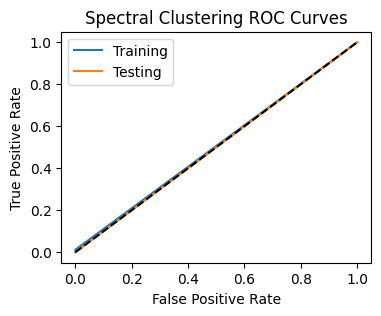

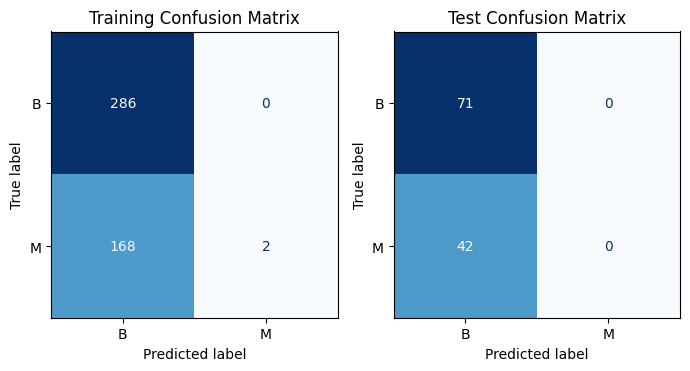

In [55]:
X = data.iloc[:, 2:]
y = data.iloc[:, 1]

all_scores = []
first_run = {}

for run in range(30):
    rng = np.random.default_rng(run + 1)

    benign = np.where(y == "B")[0]
    malignant = np.where(y == "M")[0]

    test_benign = rng.choice(benign, size = round(0.20 * len(benign)), replace = False)
    test_malignant = rng.choice(malignant, size = round(0.20 * len(malignant)), replace = False)

    test_indices = np.concatenate([test_benign, test_malignant])
    train_indices = np.setdiff1d(np.arange(len(y)), test_indices)

    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]
    train_y = y.iloc[train_indices]
    test_y = y.iloc[test_indices]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    X_all_scaled = np.vstack((X_train_scaled, X_test_scaled))

    spectral = SpectralClustering(n_clusters = 2, affinity = "rbf", gamma = 1, random_state = run + 1)

    all_clusters = spectral.fit_predict(X_all_scaled)

    train_clusters = all_clusters[:len(train_indices)]
    test_clusters = all_clusters[len(train_indices):]

    cluster_labels = ["B", "B"]
    cluster_m_scores = [0.0, 0.0]

    overall_label = train_y.value_counts().idxmax()
    overall_m_score = (train_y == "M").mean()

    for cluster in range(2):
        members = np.where(train_clusters == cluster)[0]

        if len(members) > 0:
            labels_in_cluster = train_y.iloc[members]
            cluster_labels[cluster] = labels_in_cluster.value_counts().idxmax()
            cluster_m_scores[cluster] = (labels_in_cluster == "M").mean()
        else:
            cluster_labels[cluster] = overall_label
            cluster_m_scores[cluster] = overall_m_score

    train_pred = np.array([cluster_labels[int(c)] for c in train_clusters])
    test_pred = np.array([cluster_labels[int(c)] for c in test_clusters])

    train_m_score = np.array([cluster_m_scores[int(c)] for c in train_clusters])
    test_m_score = np.array([cluster_m_scores[int(c)] for c in test_clusters])

    scores = [accuracy_score(train_y, train_pred), precision_score(train_y, train_pred, pos_label = "M", zero_division = 0), recall_score(train_y, train_pred, pos_label = "M", zero_division = 0), f1_score(train_y, train_pred, pos_label = "M", zero_division = 0), roc_auc_score(train_y == "M", train_m_score), accuracy_score(test_y, test_pred), precision_score(test_y, test_pred, pos_label = "M", zero_division = 0), recall_score(test_y, test_pred, pos_label = "M", zero_division = 0), f1_score(test_y, test_pred, pos_label = "M", zero_division = 0), roc_auc_score(test_y == "M", test_m_score)]
    all_scores.append(scores)

    if run == 0:
        first_run = {"train_y": train_y, "train_pred": train_pred, "train_score": train_m_score, "test_y": test_y, "test_pred": test_pred, "test_score": test_m_score}

columns = ["train_accuracy", "train_precision", "train_recall", "train_f1", "train_auc", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_auc"]
results = pd.DataFrame(all_scores, columns = columns)

print("Average scores over 30 runs:")
print(results.mean())

train_fpr, train_tpr, _ = roc_curve(first_run["train_y"] == "M", first_run["train_score"])
test_fpr, test_tpr, _ = roc_curve(first_run["test_y"] == "M", first_run["test_score"])

plt.figure(figsize = (4, 3))
plt.plot(train_fpr, train_tpr, label = "Training")
plt.plot(test_fpr, test_tpr, label = "Testing")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Spectral Clustering ROC Curves")
plt.legend()
plt.show()

labels = ["B", "M"]
train_cm = confusion_matrix(first_run["train_y"], first_run["train_pred"], labels = labels)
test_cm = confusion_matrix(first_run["test_y"], first_run["test_pred"], labels = labels)

fig, axes = plt.subplots(1, 2, figsize = (7, 4))
ConfusionMatrixDisplay(confusion_matrix = train_cm, display_labels = labels).plot(ax = axes[0], cmap = "Blues", values_format = "d", colorbar = False)
axes[0].set_title("Training Confusion Matrix")
ConfusionMatrixDisplay(confusion_matrix = test_cm, display_labels = labels).plot(ax = axes[1], cmap = "Blues", values_format = "d", colorbar = False)
axes[1].set_title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

#### (iv) Compare

These results mostly match what I expected because the supervised model had the best scores, and the semi-supervised model was close to it even though it started with only half of the training labels. K-means did okay, but its scores were lower than both SVM models. Spectral clustering did the worst, especially because its recall was under 1% and its AUC was about 0.505, which is close to random guessing. This suggests that with gamma = 1, its clusters did not separate the benign and malignant cases very well.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [28]:
data = pd.read_csv("/content/data_banknote_authentication.txt", header = None)

data.columns = ["variance", "skewness", "curtosis", "entropy", "class"]


X = data[["variance", "skewness", "curtosis", "entropy"]]
y = data["class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 900, test_size = 472, random_state = 1018, stratify = y)

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [35]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
pool_sizes = np.arange(10, 901, 10)

def train_svm(pool):
    model = make_pipeline(StandardScaler(), LinearSVC(penalty = "l1", dual = False, max_iter = 10000, tol = 0.001))
    search = GridSearchCV(model, {"linearsvc__C": C_values}, cv = 5, scoring = "accuracy", n_jobs = -1)

    search.fit(X_train.iloc[pool], y_train.iloc[pool])
    return search.best_estimator_

passive_errors = np.zeros((50, 90))

for run in range(50):
    rng = np.random.default_rng(run + 1)

    class_0 = np.where(y_train.to_numpy() == 0)[0]
    class_1 = np.where(y_train.to_numpy() == 1)[0]

    first_0 = rng.choice(class_0, size=5, replace = False)
    first_1 = rng.choice(class_1, size=5, replace = False)

    pool = list(np.concatenate([first_0, first_1]))

    remaining = np.setdiff1d(np.arange(len(X_train)), pool)
    rng.shuffle(remaining)

    for step in range(90):
        model = train_svm(pool)

        predictions = model.predict(X_test)
        passive_errors[run, step] = 1 - accuracy_score(y_test, predictions)

        if step < 89:
            new_points = remaining[:10]
            pool.extend(new_points)
            remaining = remaining[10:]

average_passive_error = passive_errors.mean(axis=0)

print("Average passive test errors:")
print(pd.DataFrame({"training points": pool_sizes, "test error": average_passive_error}))

Average passive test errors:
    training points  test error
0                10    0.092542
1                20    0.050424
2                30    0.041059
3                40    0.033263
4                50    0.028729
..              ...         ...
85              860    0.010212
86              870    0.010212
87              880    0.009958
88              890    0.010127
89              900    0.010381

[90 rows x 2 columns]


#### (ii) Active

In [36]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
pool_sizes = np.arange(10, 901, 10)

def train_svm(pool):
    model = make_pipeline(StandardScaler(), LinearSVC(penalty = "l1", dual = False, max_iter = 10000, tol = 0.001))
    search = GridSearchCV(model, {"linearsvc__C": C_values}, cv = 5, scoring = "accuracy", n_jobs = -1)

    search.fit(X_train.iloc[pool], y_train.iloc[pool])
    return search.best_estimator_

active_errors = np.zeros((50, 90))

for run in range(50):
    rng = np.random.default_rng(run + 1)

    class_0 = np.where(y_train.to_numpy() == 0)[0]
    class_1 = np.where(y_train.to_numpy() == 1)[0]

    first_0 = rng.choice(class_0, size=5, replace = False)
    first_1 = rng.choice(class_1, size=5, replace = False)

    pool = list(np.concatenate([first_0, first_1]))
    remaining = np.setdiff1d(np.arange(len(X_train)), pool)

    for step in range(90):
        model = train_svm(pool)

        predictions = model.predict(X_test)
        active_errors[run, step] = 1 - accuracy_score(y_test, predictions)

        if step < 89:
            distances = np.abs(model.decision_function(X_train.iloc[remaining]))

            closest_positions = np.argsort(distances)[:10]
            new_points = remaining[closest_positions]

            pool.extend(new_points)
            remaining = np.delete(remaining, closest_positions)

average_active_error = active_errors.mean(axis = 0)

print("Average active test errors:")
print(pd.DataFrame({"training points": pool_sizes, "test error": average_active_error}))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Average active test errors:
    training points  test error
0                10    0.088347
1                20    0.054364
2                30    0.040466
3                40    0.025805
4                50    0.017076
..              ...         ...
85              860    0.009746
86              870    0.009576
87              880    0.009788
88              890    0.010381
89              900    0.010551

[90 rows x 2 columns]


### (c) Average the 50 test errors

    training points  passive error  active error
0                10       0.092542      0.088347
1                20       0.050424      0.054364
2                30       0.041059      0.040466
3                40       0.033263      0.025805
4                50       0.028729      0.017076
..              ...            ...           ...
85              860       0.010212      0.009746
86              870       0.010212      0.009576
87              880       0.009958      0.009788
88              890       0.010127      0.010381
89              900       0.010381      0.010551

[90 rows x 3 columns]
Active learning had lower error at 38 out of 90.


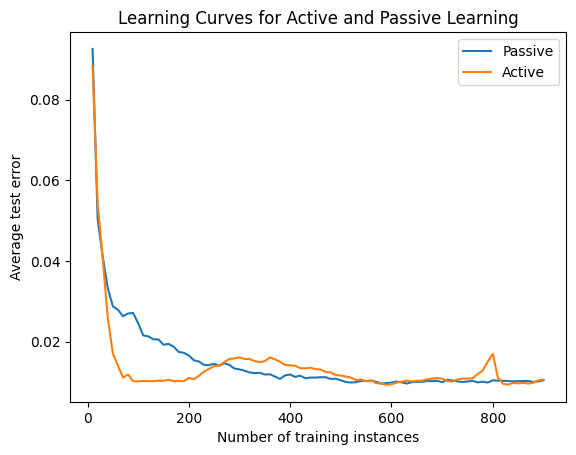

In [40]:
average_passive_error = passive_errors.mean(axis = 0)
average_active_error = active_errors.mean(axis = 0)

pool_sizes = np.arange(10, 901, 10)
error_results = pd.DataFrame({"training points": pool_sizes, "passive error": average_passive_error, "active error": average_active_error})
print(error_results)
print("Active learning had lower error at", np.sum(average_active_error < average_passive_error),"out of 90.")

plt.plot(pool_sizes, average_passive_error, label = "Passive")
plt.plot(pool_sizes, average_active_error, label = "Active")
plt.xlabel("Number of training instances")
plt.ylabel("Average test error")
plt.title("Learning Curves for Active and Passive Learning")
plt.legend()
plt.show()

Both methods had lower test error as more training points were added. Active learning improved faster at the beginning, and at 50 points its error was about 0.017 compared to 0.029 for passive learning. But active learning was not always better. It had lower error at only 38 out of 90 pool sizes. By the end, both methods were around 1% test error, so they ended up performing about the same. Overall, active learning helped more early on, but it did not stay better than passive learning the whole time.